# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [1]:
import pandas as pd

flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")


Display the first five rows of the DataFrame.


In [2]:
flights.head()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [3]:
flights.tail()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [4]:
flights.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   airline                5000 non-null   object
 1   origin_city            5000 non-null   object
 2   destination_city       5000 non-null   object
 3   distance_miles         5000 non-null   int64 
 4   arrival_delay_minutes  5000 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 195.4+ KB


**How many observations are in the DataFrame?**

Your answer:

There are 5,000 observations (rows) in the DataFrame, one per sampled flight, with 5 features.


Count the missing values in every feature.


In [5]:
flights.isnull().sum()


airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | object | categorical | 0 |
| `origin_city` | object | categorical | 0 |
| `destination_city` | object | categorical | 0 |
| `distance_miles` | int64 | quantitative | 0 |
| `arrival_delay_minutes` | int64 | quantitative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [6]:
destination_counts = flights["destination_city"].value_counts()
destination_counts


destination_city
Chicago, IL                       296
Atlanta, GA                       222
Dallas/Fort Worth, TX             210
Denver, CO                        209
Washington, DC                    165
                                 ... 
Gunnison, CO                        1
Allentown/Bethlehem/Easton, PA      1
Idaho Falls, ID                     1
Jamestown, ND                       1
Yuma, AZ                            1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


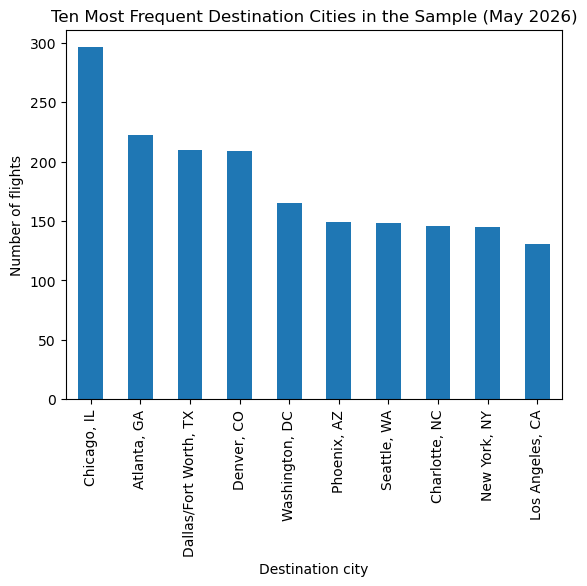

In [7]:
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar")
plt.title("Ten Most Frequent Destination Cities in the Sample (May 2026)")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**Which destination city is most common in the sample?**

Your answer:

Chicago, IL is the most common destination in the sample with 296 of the 5,000 flights. Atlanta, GA is second with 222, then Dallas/Fort Worth, TX with 210 and Denver, CO with 209.


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


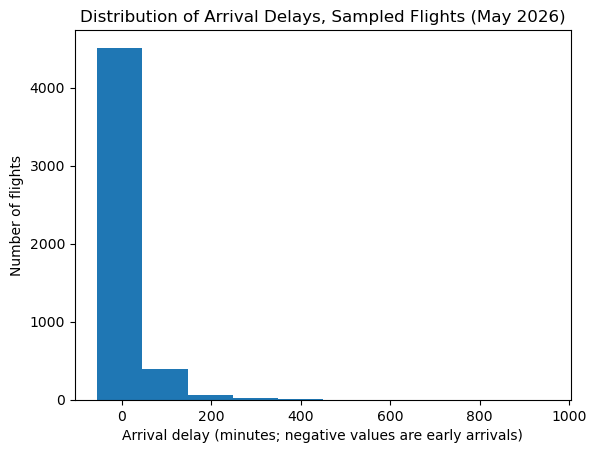

In [8]:
flights["arrival_delay_minutes"].plot(kind="hist")
plt.title("Distribution of Arrival Delays, Sampled Flights (May 2026)")
plt.xlabel("Arrival delay (minutes; negative values are early arrivals)")
plt.ylabel("Number of flights")
plt.show()


**Approximately what arrival-delay value appears most common?**

Your answer:

The tallest bar is the first one, which covers roughly -55 to about 45 minutes, so the most common delay is somewhere near zero. My read from the chart is that the typical flight is a few minutes early, around -5 to -10 minutes, but the default bins are too wide to pin it down any closer than that.


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer:

The horizontal axis runs from about -55 minutes (the earliest arrival) to a little under 1,000 minutes (the latest), so the range is roughly 1,000 minutes.


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:

Strongly right-skewed. Almost every flight is piled into the first bar near zero and there is a long, thin tail of large delays stretching to the right. There is nothing comparable on the left because a flight can only arrive so early.


Display a numerical summary of `arrival_delay_minutes`.


In [9]:
flights["arrival_delay_minutes"].describe()


count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [10]:
flights["arrival_delay_minutes"].mode()


0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer:

The calculated mode is -8 minutes. My estimate of about -5 to -10 minutes was close, within a few minutes. The histogram could only tell me the peak was near zero and slightly early; it could not show a single exact value because the default bin is about 100 minutes wide.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer:

They matched well. `.describe()` gives a minimum of -55 and a maximum of 953 minutes, so the actual range is 1,008 minutes. I estimated about -55 to just under 1,000, which is right, because the two extreme values are what set the ends of the horizontal axis in the first place.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer:

The mean (6.10 minutes) is greater than the median (-6 minutes). The typical flight in the middle of the data arrived 6 minutes early, but the average is a 6 minute delay.


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer:

The mean is pulled toward the long right tail. A handful of flights that were delayed hundreds of minutes (the maximum is 953) add a lot to the total that the mean divides up, while the median only cares about the middle position and ignores how extreme the tail values are. When the mean sits to the right of the median like this, it is a sign the distribution is right-skewed, which is exactly what the histogram shows.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


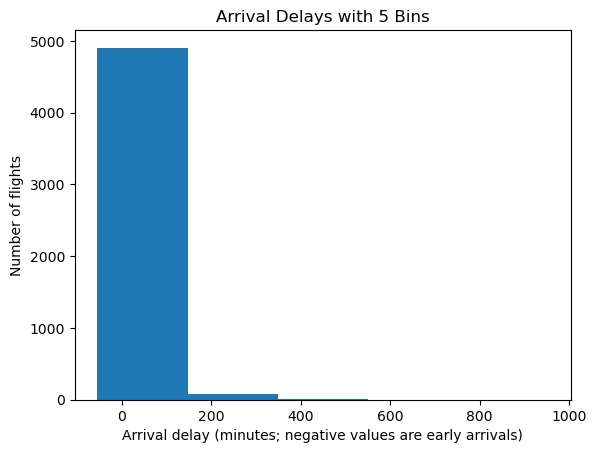

In [11]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=5)
plt.title("Arrival Delays with 5 Bins")
plt.xlabel("Arrival delay (minutes; negative values are early arrivals)")
plt.ylabel("Number of flights")
plt.show()


Re-create the arrival-delay histogram using exactly 25 bins.


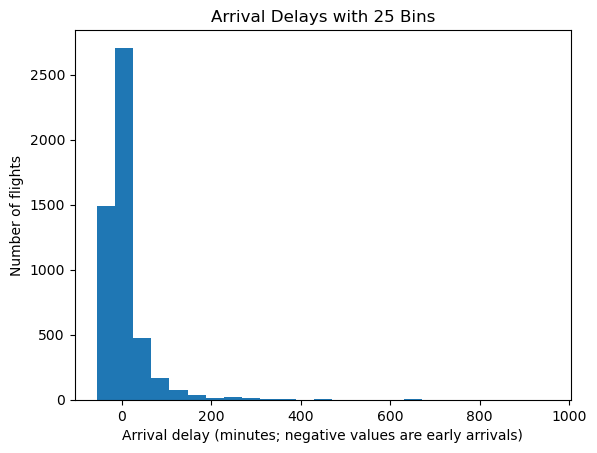

In [12]:
flights["arrival_delay_minutes"].plot(kind="hist", bins=25)
plt.title("Arrival Delays with 25 Bins")
plt.xlabel("Arrival delay (minutes; negative values are early arrivals)")
plt.ylabel("Number of flights")
plt.show()


**What changed when the number of bins was reduced to 5?**

Your answer:

With 5 bins each bar covers about 200 minutes, so 4,905 of the 5,000 flights land in the single first bar (-55 to about 147 minutes). The shape of the distribution disappears. You can no longer see where the peak is or that most flights are early, and the tail is reduced to a few bars that are barely visible.


**What changed when the number of bins was increased to 25?**

Your answer:

With 25 bins each bar covers about 40 minutes, and the peak splits into two bars: about 1,488 flights from -55 to -15 minutes and about 2,708 flights from -15 to 26 minutes. Now you can see that most flights are early or close to on time, and the tail becomes a string of small but visible bars out to 953 minutes. The downside is that most of the horizontal axis is almost empty because the extreme delays stretch it so far.


**Which bin setting communicates the distribution most clearly?**

Your answer:

The 25-bin histogram communicates the distribution most clearly. It shows the location of the peak, that the bulk of flights are early or on time, and the long right tail, without becoming noisy. The default 10 bins is acceptable but blurs the peak into one bar, and 5 bins hides the shape altogether. Even with 25 bins, a version limited to about -60 to 200 minutes would show the bulk of the data better, since so few flights fall beyond that.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


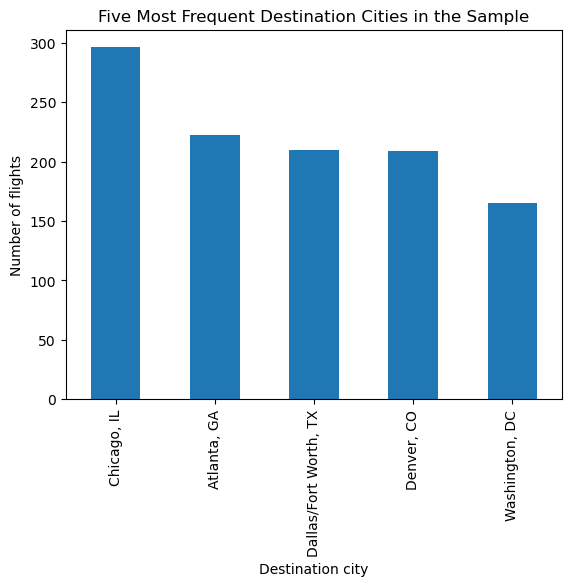

In [13]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


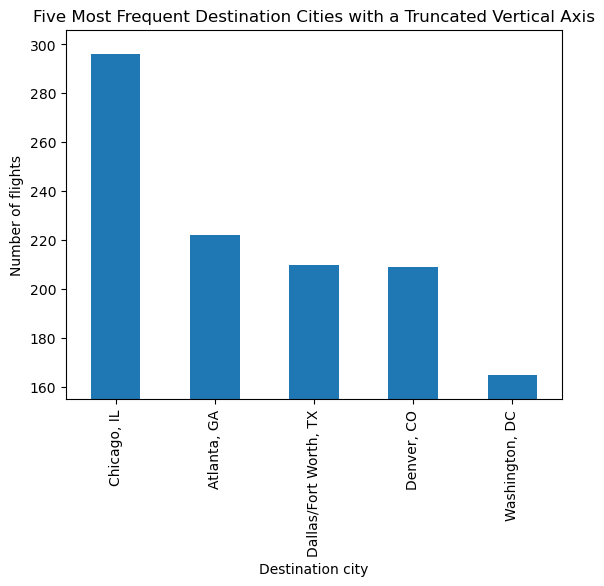

In [14]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:

The truncated axis starts at 155 instead of 0, so the bars only show the differences above that floor. Chicago (296) looks like it has several times as many flights as Atlanta (222) and Washington, DC (165) is reduced to a sliver, when in reality Chicago has about 1.3 times Atlanta's count and about 1.8 times Washington's. The real differences are there, but the chart exaggerates them.


**Which chart communicates the counts more honestly?**

Your answer:

The first chart, with the full zero baseline, communicates the counts honestly. Bar height is proportional to the number of flights, so the visual comparison between cities matches the actual ratio of their counts.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer:

May 2026. The source data is the BTS Reporting Carrier On-Time Performance data for that one month, 611,735 domestic flight records.


**Which flights were eligible to be included in the sample?**

Your answer:

Completed, non-diverted domestic flights with recorded values for all five selected features (airline, origin city, destination city, distance, and arrival delay). The sample is a reproducible random draw of 5,000 of those eligible flights.


**Which flights and records were excluded before the sample was selected?**

Your answer:

Canceled flights, diverted flights, and any record that was missing a value for one or more of the five selected features were all excluded before the sample was drawn.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer:

No. The records with missing values were removed before sampling, so the sample was built to have no missing values. Finding zero missing values here only tells us the cleaning step worked. It says nothing about how many of the original 611,735 BTS records had missing fields.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer:

Because canceled and diverted flights were never eligible to be in the sample. Every flight in this data completed its trip to its scheduled destination, and those flights could easily behave differently from flights that were diverted (for example, a diverted flight might have a much larger arrival delay or no meaningful arrival delay at all). The sample describes the eligible flights and nothing more.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer:

A bar chart. Airline is a categorical feature and the question is about the count of flights in each category. There are 13 airlines in the sample, which is too many slices for a pie chart to read well but is a comfortable number of bars, and bar heights make it easy to compare the airlines directly.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer:

A pie chart. Early, on time, and delayed are three categories that split every flight into exactly one group, and the question is about the proportion of the whole in each. Three slices are easy to read. A bar chart of percentages would also work, but the pie emphasizes that the three shares add up to all 5,000 flights (about 61.5% early, 1.6% on time, 36.9% delayed).


**Which chart would you use to show the distribution of flight distances?**

Your answer:

A histogram. Flight distance in miles is a quantitative feature, and a histogram groups the distances into bins so you can see the shape of the distribution, the typical distance, the range, and whether it is skewed. Bar and pie charts are for categories, not measurements.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer:

**Video Game Sales** (file `vgsales.csv`), created by Gregory Smith (Kaggle user gregorut) and published on Kaggle: <https://www.kaggle.com/datasets/gregorut/videogamesales>. The data dictionary is the "Fields include" list in the About Dataset section of that same page (there is no separate dictionary file): <https://www.kaggle.com/datasets/gregorut/videogamesales> under About Dataset.

The dataset was generated by a scrape of vgchartz.com and lists video games with sales greater than 100,000 copies. It has 16,598 records; the creator notes that 2 records were dropped for incomplete information. Each row is one game on one platform, so a title released on several platforms appears once per platform (for example, Grand Theft Auto V appears on PS3, X360, and PS4). The features are the sales ranking, name, platform, release year, genre, publisher, and sales in North America, Europe, Japan, and the rest of the world, in millions of copies, plus total global sales. The time period is not documented on the page; the release years in the file run from 1980 to 2020, and the Kaggle page shows the dataset was last updated about 10 years ago (2016), so the few 2017 and 2020 years are suspect. Geographic coverage is worldwide, split into the four sales regions. The license is listed as Unknown. This is the same file used as the Video Game Stats dataset in my Probability course, so I already knew its structure.


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [15]:
vgsales_df = pd.read_csv("data/vgsales.csv")

display(vgsales_df.head())
print("Shape (rows, columns):", vgsales_df.shape)
vgsales_df.info()
print()
print("Missing values per feature:")
print(vgsales_df.isnull().sum())


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


Shape (rows, columns): (16598, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB

Missing values per feature:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| `Rank` | Ranking of overall sales (1 = best-selling game) | identifier | int64 | 0 |
| `Name` | The game's name | categorical (text label; 11,493 unique names) | object | 0 |
| `Platform` | Platform of the game's release (i.e. PC, PS4, etc.); 31 platform codes | categorical | object | 0 |
| `Year` | Year of the game's release | date/time (release year) | float64 | 271 |
| `Genre` | Genre of the game; 12 genres | categorical | object | 0 |
| `Publisher` | Publisher of the game; 578 publishers | categorical | object | 58 |
| `NA_Sales` | Sales in North America (in millions of copies) | quantitative | float64 | 0 |
| `EU_Sales` | Sales in Europe (in millions of copies) | quantitative | float64 | 0 |
| `JP_Sales` | Sales in Japan (in millions of copies) | quantitative | float64 | 0 |
| `Other_Sales` | Sales in the rest of the world (in millions of copies) | quantitative | float64 | 0 |
| `Global_Sales` | Total worldwide sales (in millions of copies) | quantitative | float64 | 0 |

**Missing-value codes or other data preparation, if applicable:**

Your answer:

The data dictionary does not define any special missing-value codes. In the CSV the missing release years and publishers are written as the text `N/A`, which Pandas reads as missing (NaN) by default, so the counts above come straight from `.isnull().sum()`: 271 games have no release year and 58 have no publisher. Because of the blanks, `Year` is stored as float64 instead of int64. I kept every row; the 271 games without a year would only need to be set aside for a year-based analysis, which I do not do in this lab. `Rank` is a numeric identifier, not a measurement, so I do not treat it as quantitative. One note from inspecting the data: four rows have release years of 2017 or 2020, which is after the dataset was last updated, so those years are probably entry errors in the source; I left them as recorded.


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


Games shown: 15747 | games at 2 million or more excluded from view: 851


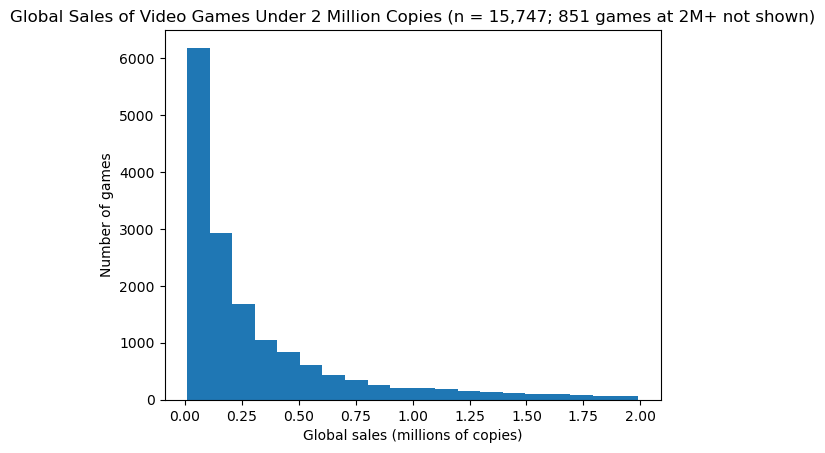

In [16]:
# 851 of the 16,598 games (5.1%) sold 2 million copies or more, with a maximum of
# 82.74 million (Wii Sports). Plotting the full range squeezes the other 95% into one
# bar, so this histogram shows the 15,747 games under 2 million copies.
under_2m = vgsales_df.loc[vgsales_df["Global_Sales"] < 2, "Global_Sales"]
excluded = (vgsales_df["Global_Sales"] >= 2).sum()
print("Games shown:", len(under_2m), "| games at 2 million or more excluded from view:", excluded)

under_2m.plot(kind="hist", bins=20)
plt.title(f"Global Sales of Video Games Under 2 Million Copies (n = {len(under_2m):,}; {excluded} games at 2M+ not shown)")
plt.xlabel("Global sales (millions of copies)")
plt.ylabel("Number of games")
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer:

I chose `Global_Sales`, total worldwide sales in millions of copies. It is a quantitative measurement (not an identifier), so a histogram is the right chart for showing how the values are distributed. I limited the view to games under 2 million copies and said so in the title, because the 851 games above that line, topped by Wii Sports at 82.74 million, stretch the axis so far that the full-range histogram is a single bar.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:

The distribution is strongly right-skewed: the first bar (about 0.01 to 0.11 million copies) holds the most games, roughly 6,200, the second bar drops to about 2,900, and each bar after that is shorter than the one before. The median game in this dataset sold 0.17 million copies and the mean is 0.54 million, with the mean pulled up by the long tail of big sellers. About three quarters of the games sold under half a million copies, while a small number sold tens of millions. These numbers describe the games in this file (titles that sold over 100,000 copies, as scraped from vgchartz.com), not the video game market as a whole.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1310
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64


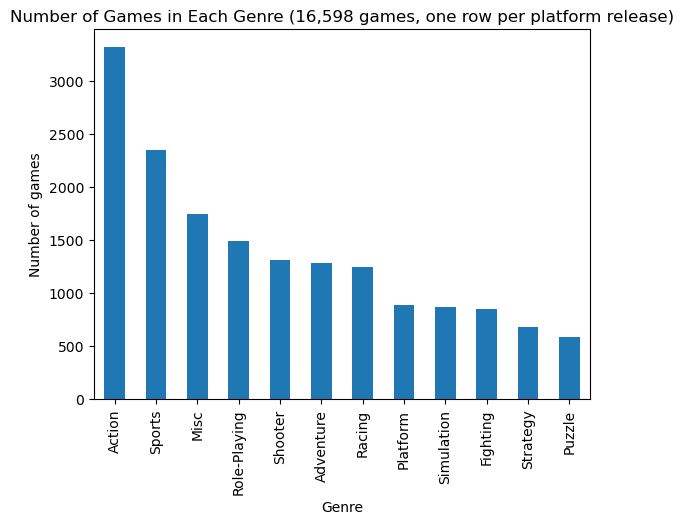

In [17]:
genre_counts = vgsales_df["Genre"].value_counts()
print(genre_counts)

genre_counts.plot(kind="bar")
plt.title("Number of Games in Each Genre (16,598 games, one row per platform release)")
plt.xlabel("Genre")
plt.ylabel("Number of games")
plt.show()


**Which feature did you choose, and why is this chart appropriate?**

Your answer:

I chose `Genre`. It is a categorical feature with 12 categories and no missing values, which is a manageable number of bars, and the question of interest is how many games fall in each genre, so a bar chart of `.value_counts()` is the natural choice. Every one of the 16,598 rows is counted once, with no exclusions.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:

Action is by far the most common genre with 3,316 games, about 20% of the dataset, followed by Sports with 2,346 and Misc with 1,739. Puzzle is the least common with 582 games, so there are about 5.7 times as many Action games as Puzzle games in this file. The counts fall off fairly steadily from left to right rather than splitting into a few large and a few tiny genres.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:

- **Tool used:** Claude (Anthropic), working with me in Claude Code on my laptop.
- **What I asked it to help with:** writing and checking the Pandas and matplotlib code for each cell, computing the numbers I quote in my answers, and drafting the written responses, which I read, edited, and approved before submitting. The dataset choice was mine; I had already used this file in my Probability course.
- **One suggestion I checked against my code, chart, or output:** it suggested limiting the `Global_Sales` histogram to games under 2 million copies. I ran the full-range histogram first and saw it was one bar at zero with an empty axis out to 82.74, so I confirmed the problem it was solving, then checked the excluded count (851 games, 5.1%) against `(vgsales_df["Global_Sales"] >= 2).sum()` before accepting the clipped chart with that count in the title.
- **What I accepted, modified, or rejected, and why:** I accepted the code after running every cell top to bottom and confirming the numbers in the answers match the displayed output (for example, mode -8, mean 6.10, median -6, and the 5-bin count of 4,905). I kept the interpretations in my own words and tied each one to a value visible in the chart or output.


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
